# Google Play Store - Complete EDA
### A step-by-step exploratory data analysis, written so it can be reused on any dataset

**Dataset:** [Google Play Store Apps](https://www.kaggle.com/datasets/lava18/google-play-store-apps/) (Kaggle).

Each row is one app, with its category, rating, size, number of installs, price, content rating, genre and version info.

### About the dataset

**Context** - While many public datasets provide Apple App Store data, there are not many counterpart datasets for
Google Play Store apps. The iTunes App Store page uses a nicely indexed, appendix-like structure that makes scraping
simple. Google Play Store uses dynamic page loading, which makes scraping harder - so this dataset is comparatively rare.

**Content** - Each app (row) has values for category, rating, size, installs, price and more.

**Acknowledgements** - This information is scraped from the Google Play Store.

**Inspiration** - The Play Store data has enormous potential to guide app-making businesses. Actionable insights can be
drawn for developers to capture the Android market.

---
## How to reuse this notebook

Every EDA follows the same ten moves, in the same order. The sections below **are** those ten moves - so on the
next dataset I keep the headings, keep the order, and only swap the column names.

| # | Section | The move | The question it answers |
|---|---------|----------|-------------------------|
| 1 | 1-2 | Load and look | What am I holding? How many rows, what columns, what types? |
| 2 | 3 | Fix the types | Which columns are numbers pretending to be text? |
| 3 | 4 | Duplicates | Am I counting the same thing twice? |
| 4 | 5 | Missing values | What is missing, and **why** is it missing? |
| 5 | 6 | Feature building | Which columns do I need that don't exist yet? |
| 6 | 7 | Univariate | What does each column look like on its own? |
| 7 | 8 | Bivariate | How do columns move together? |
| 8 | 9 | Correlation | Which pairs are worth a closer look? |
| 9 | 10 | Statistical tests | Is the pattern real, or am I just squinting at a chart? |
| 10 | 11-14 | Answer, summarise, caveat, save | So what? And what can this data *not* tell me? |

The rule followed in every cell below: **one idea per cell**, a markdown line above saying *why*, and an
**Observation** below saying *what I learned*. If a cell needs a paragraph to explain it, it is doing too much -
split it.

Section **15** at the end is the cheat sheet: step to pandas function.

---

## 1. Import the libraries

In [ ]:
import pandas as pd              
import numpy as np               
import matplotlib.pyplot as plt  
import seaborn as sns            
%matplotlib inline   
# tLast line ells Jupyter to draw charts inside the notebook instead of in a separate window


Two housekeeping settings.

By default pandas hides columns and rows with `...` when a table is wide or long. That is fine for a quick peek,
but during an EDA I want to see everything.

In [2]:
pd.set_option('display.max_columns', None)   # None = no limit, show every column
pd.set_option('display.max_rows', None)      # None = no limit, show every row

Pandas and seaborn print a lot of deprecation warnings that have nothing to do with our analysis.
Silencing them keeps the notebook readable.

> Do this **after** the code works, not before - a warning you hide early is a bug you find late.

In [3]:
import warnings
warnings.filterwarnings('ignore')

Finally, a default chart size and style, so I don't have to repeat `plt.figure(figsize=(12, 5))`
in front of every single plot.

In [4]:
sns.set_style('whitegrid')                 # faint grid behind the plots, easier to read values off
plt.rcParams['figure.figsize'] = (12, 5)   # default (width, height) in inches for every chart

---
## 2. Load the data and take a first look

Keeping the file path in its own variable is the single most useful habit for reuse:
when I point this notebook at a different dataset, **this is the only line I change**.

In [5]:
csv_path = './googleplaystore.csv'   # <-- the one line to change when reusing this notebook

df = pd.read_csv(csv_path)           # read_csv() reads the file and returns a DataFrame (a table)

- First, the top five rows, just to see what a record actually looks like.

In [6]:
df.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


- How big is this table?

`df.shape` returns a pair: `(number of rows, number of columns)`. Position `[0]` is the rows,
position `[1]` is the columns.

In [7]:
print(f"Rows:    {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

Rows:    10841
Columns: 13


- And the exact column names - handy to copy from later, so I don't retype and misspell them.

In [8]:
df.columns

Index(['App', 'Category', 'Rating', 'Reviews', 'Size', 'Installs', 'Type',
       'Price', 'Content Rating', 'Genres', 'Last Updated', 'Current Ver',
       'Android Ver'],
      dtype='object')

- `df.info()` is the most useful single command in an EDA. For every column it gives three things at once:
the **data type**, the **non-null count** (so I can spot missing values), and the memory used.

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10840 non-null  object 
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  int64  
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  object 
 6   Type            10840 non-null  object 
 7   Price           10841 non-null  object 
 8   Content Rating  10841 non-null  object 
 9   Genres          10840 non-null  object 
 10  Last Updated    10841 non-null  object 
 11  Current Ver     10833 non-null  object 
 12  Android Ver     10839 non-null  object 
dtypes: float64(1), int64(1), object(11)
memory usage: 1.1+ MB


## Observations
---
1. 10,841 rows and 13 columns.
2. Only `Rating` (float) and `Reviews` (int) are stored as numbers. Everything else is `object`, which in
   pandas means *text*.
3. But look at the data: `Size` holds `'19M'`, `Installs` holds `'10,000+'`, `Price` holds `'$4.99'`.
   Those **are** numbers - they are just stuck as text because of the units and symbols.
4. Several columns have fewer non-null values than 10,841, so there are missing values to deal with.
---

- `df.describe()` gives the summary statistics - but **only for the numeric columns**.
That limitation is itself informative: it shows exactly how much of the data pandas currently considers usable.

In [10]:
df.describe()

,Rating,Reviews
count,9367.000000,1.084100e+04
mean,4.191513,4.441119e+05
std,0.515735,2.927629e+06
min,1.000000,0.000000e+00
25%,4.000000,3.800000e+01
50%,4.300000,2.094000e+03
75%,4.500000,5.476800e+04
max,5.000000,7.815831e+07


## Observations
---
- Only **2** columns show up here, which confirms the problem above: pandas can only do maths on `Rating` and `Reviews`.
- `Rating` runs from 1 to 5 with a mean around 4.19 - people are generous raters.
- `Reviews` runs from 0 to 78 million with a mean of ~444,000. A mean that far above the middle of the range is a
  strong hint that the column is heavily skewed by a few giant apps. More on that in section 7.
- **Next step:** convert `Size`, `Installs` and `Price` into real numbers so this table becomes useful.
---

---
## 3. Fixing the columns that are numbers stored as text

This is almost always the first cleaning job on a real dataset. Until `Price` is a number I cannot average it,
plot it, or correlate it with anything. Three columns need fixing here: `Size`, `Installs`, `Price`.

The method is the same every time:
1. Look at the distinct values to learn what shapes exist.
2. Count each shape, and check the counts add up to the number of rows - that proves no shape was missed.
3. Write the conversion, **test it on a few values**, then apply it.
4. Verify against a number already known.

### 3.1 `Size`

- Step 1: what distinct values are in there? `.unique()` lists them; `[:15]` takes the first 15 so the output stays readable.

In [11]:
df['Size'].unique()[:15]

array(['19M', '14M', '8.7M', '25M', '2.8M', '5.6M', '29M', '33M', '3.1M',
       '28M', '12M', '20M', '21M', '37M', '2.7M'], dtype=object)

## Observations
---
Three shapes of value:
1. Megabytes - `'19M'`
2. Kilobytes - `'404k'`
3. The text `'Varies with device'` - a size that genuinely has no single number behind it
---

- Step 2: count each shape and check the total.

`str.contains('M')` returns a True/False value for every row, and `.sum()` counts the Trues
(because in Python `True` counts as 1 and `False` as 0 - a trick worth using constantly).

In [12]:
in_mb  = df['Size'].str.contains('M').sum()
in_kb  = df['Size'].str.contains('k').sum()
varies = df['Size'].str.contains('Varies with device').sum()

print(f"Values in MB:          {in_mb}")
print(f"Values in kB:          {in_kb}")
print(f"'Varies with device':  {varies}")
print(f"Total accounted for:   {in_mb + in_kb + varies}")
print(f"Rows in the data:      {len(df)}")

Values in MB:          8830
Values in kB:          316
'Varies with device':  1695
Total accounted for:   10841
Rows in the data:      10841


## Observations
---
The three counts add up to exactly 10,841 - every row is one of the three shapes, with no fourth surprise
hiding in there. **This check is worth the thirty seconds it takes.** If the totals had not matched, there
would be an unknown value shape that the conversion function would silently mangle.
---

- Step 3: write the conversion.

The plan in plain English: strip any stray spaces, look at the **last character**, and multiply accordingly.
1 kB = 1024 bytes, 1 MB = 1024 x 1024 bytes. `'Varies with device'` becomes `NaN` (pandas' "missing") because
there is no honest number to put there.

In [13]:
def convert_size(size):
    """
    Convert a size like '19M' or '404k' into a plain number of bytes.
    'Varies with device' has no real number behind it, so it becomes NaN (missing).
    """
    if not isinstance(size, str):          # not text? (already a number, or missing) - treat as missing
        return np.nan

    size = size.strip()                    # remove stray spaces at either end

    if size.endswith('M'):                 # e.g. '19M'
        return float(size[:-1]) * 1024 * 1024    # size[:-1] = everything except the last character

    if size.endswith('k'):                 # e.g. '404k'
        return float(size[:-1]) * 1024

    return np.nan                          # anything else, i.e. 'Varies with device' 

> **A trap worth knowing.** A natural-looking version of this function lowercases the text first
> (`size = size.lower()`) and then calls `size.replace('M', '')`. After lowercasing there is no capital `M`
> left, so nothing gets removed, and `float('19m')` raises a `ValueError`. Whenever you change the case of a
> string, every later comparison has to use the same case. Using `endswith()` on the original text avoids the
> whole problem.

- Step 3b: **test the function on a handful of values before running it on 10,000 rows.**
This is thirty seconds that regularly saves an hour.

In [14]:
print(convert_size('19M'))
print(convert_size('404k'))
print(convert_size('Varies with device'))

19922944.0
413696.0
nan


## Observations
---
- `19M` -> 19,922,944 bytes (19 x 1024 x 1024). Correct.
- `404k` -> 413,696 bytes (404 x 1024). Correct.
- `Varies with device` -> `nan`. Correct.

The function behaves. Now apply it.
---

- Step 4: apply it. `.apply()` runs the function once for every value in the column.

In [15]:
df['Size'] = df['Size'].apply(convert_size)

- The column now holds bytes, not `'19M'`, so the name `Size` is misleading. Renaming it means nobody
(including me, in three months) misreads the unit.

In [16]:
df = df.rename(columns={'Size': 'Size_in_bytes'})

> **Why assign back instead of `inplace=True`?** Both work, but `df = df.rename(...)` reads as
> "make a new version of df", which is easier to follow when cells get re-run out of order. `inplace=True` is
> also being phased out in newer pandas versions, so the assign-back habit ages better.

- Bytes are hard to read. A megabytes column alongside it costs one line and makes every later chart legible.

In [17]:
df['Size_in_Mb'] = df['Size_in_bytes'] / (1024 * 1024)

df[['Size_in_bytes', 'Size_in_Mb']].head()

,Size_in_bytes,Size_in_Mb
0,19922944.0,19.0
1,14680064.0,14.0
2,9122611.2,8.7
3,26214400.0,25.0
4,2936012.8,2.8


- Step 5: verify against a number already known. The missing sizes should equal the `'Varies with device'` count.

In [18]:
print(f"Missing sizes now:            {df['Size_in_bytes'].isnull().sum()}")
print(f"'Varies with device' count:   {varies}")

Missing sizes now:            1695
'Varies with device' count:   1695


## Observations
---
The two numbers match, so the conversion did exactly what was intended and nothing else went missing along
the way. **Checking a transformation against a number you already knew is the cheapest bug-catcher there is.**
---

### 3.2 `Installs`

In [19]:
df['Installs'].unique()

array(['10,000+', '500,000+', '5,000,000+', '50,000,000+', '100,000+',
       '50,000+', '1,000,000+', '10,000,000+', '5,000+', '100,000,000+',
       '1,000,000,000+', '1,000+', '500,000,000+', '50+', '100+', '500+',
       '10+', '1+', '5+', '0+', '0'], dtype=object)

## Observations
---
- Values look like `'10,000+'` - two things in the way: the thousands **comma** and the trailing **plus sign**.
- There are no missing values and no odd text, so this is a straight string clean-up.
- Note that `'10,000+'` really means "somewhere between 10,000 and 50,000 installs". Keeping the lower
  bound is the honest reading, but it gets flagged again in the limitations section.
---

- Removing them one step at a time. Chaining all three onto one line works, but when it breaks you
cannot tell which step broke it.

`regex=False` tells pandas to treat `'+'` as a literal plus sign. Without it, pandas reads `'+'` as a regular
expression symbol (meaning "one or more of the previous thing") and the replacement misbehaves.

In [20]:
# Step 1: remove the '+' sign
df['Installs'] = df['Installs'].str.replace('+', '', regex=False)

# Step 2: remove the thousands commas
df['Installs'] = df['Installs'].str.replace(',', '', regex=False)

# Step 3: now that only digits are left, convert the text into whole numbers
df['Installs'] = df['Installs'].astype(int)

df['Installs'].head()

0       10000
1      500000
2     5000000
3    50000000
4      100000
Name: Installs, dtype: int32

- Quick check that the type really changed.

In [21]:
print(f"Data type: {df['Installs'].dtype}")
print(f"Maximum installs: {df['Installs'].max():,}")

Data type: int32
Maximum installs: 1,000,000,000


### 3.3 `Price`

In [22]:
df['Price'].unique()[:15]

array(['0', '$4.99', '$3.99', '$6.99', '$1.49', '$2.99', '$7.99', '$5.99',
       '$3.49', '$1.99', '$9.99', '$7.49', '$0.99', '$9.00', '$5.49'],
      dtype=object)

## Observations
---
Only one symbol in the way - the `$`. Free apps are stored as the string `'0'`, which converts cleanly.
---

- Same pattern as above. Note `float` here, not `int`: prices have decimals, and `int` would silently
throw away the cents.

In [23]:
df['Price'] = df['Price'].str.replace('$', '', regex=False)   # drop the dollar sign
df['Price'] = df['Price'].astype(float)                       # prices have decimals -> float

- An f-string summary. `:.2f` inside the braces means "format with 2 decimal places",
and `:,` means "use thousands separators" - two formatting tricks worth memorising.

In [24]:
print(f"Cheapest app:   $ {df['Price'].min():.2f}")
print(f"Most expensive: $ {df['Price'].max():.2f}")
print(f"Average price:  $ {df['Price'].mean():.2f}")

Cheapest app:   $ 0.00
Most expensive: $ 400.00
Average price:  $ 1.03


- Final check on all the types before moving on.

In [25]:
df.dtypes

App                object
Category           object
Rating            float64
Reviews             int64
Size_in_bytes     float64
Installs            int32
Type               object
Price             float64
Content Rating     object
Genres             object
Last Updated       object
Current Ver        object
Android Ver        object
Size_in_Mb        float64
dtype: object

## Observations
---
There are now **6** usable numeric columns instead of 2: `Rating`, `Reviews`, `Size_in_bytes`, `Size_in_Mb`,
`Installs`, `Price`. Everything downstream in this notebook depends on this section being right.
---

---
## 4. Duplicates

Check this **before** any analysis, because a duplicated row quietly double-counts everything: the category
looks bigger than it is, the averages shift, and nothing warns you.

- First, fully identical rows. `df.duplicated()` marks a row `True` if an identical row has already
appeared above it, and `.sum()` counts those marks.

In [26]:
df.duplicated().sum()

483

- But an app should only appear once by name. So let's also count duplicated **app names**.

In [27]:
df['App'].duplicated().sum()

1181

## Observations
---
A big gap: 483 fully identical rows, but 1,181 duplicated app names. So there are hundreds of apps that appear
more than once **without** being identical rows. Before deciding what to do, look at some.
---

- `keep=False` marks **every** copy as a duplicate (not just the second and later ones), so the full set
can be seen side by side.

In [28]:
repeated = df[df['App'].duplicated(keep=False)]   # keep=False -> mark every copy
repeated = repeated.sort_values('App')            # sort so copies sit next to each other

repeated[['App', 'Category', 'Reviews', 'Last Updated']].head(10)

,App,Category,Reviews,Last Updated
1393,10 Best Foods for You,HEALTH_AND_FITNESS,2490,"February 17, 2017"
1407,10 Best Foods for You,HEALTH_AND_FITNESS,2490,"February 17, 2017"
2543,1800 Contacts - Lens Store,MEDICAL,23160,"July 27, 2018"
2322,1800 Contacts - Lens Store,MEDICAL,23160,"July 27, 2018"
2385,2017 EMRA Antibiotic Guide,MEDICAL,12,"January 27, 2017"
2256,2017 EMRA Antibiotic Guide,MEDICAL,12,"January 27, 2017"
1337,21-Day Meditation Experience,HEALTH_AND_FITNESS,11506,"August 2, 2018"
1434,21-Day Meditation Experience,HEALTH_AND_FITNESS,11506,"August 2, 2018"
3083,365Scores - Live Scores,SPORTS,666521,"July 29, 2018"
5415,365Scores - Live Scores,SPORTS,666246,"July 29, 2018"


## Observations
---
Same app, same category, but **different review counts and different `Last Updated` dates**. These were
scraped more than once at different points in time.

That tells me what rule to use. "Keep whichever row happened to come first in the file" would be arbitrary.
Keeping the copy with the **most reviews** keeps the most recent, most complete snapshot of each app.

> The transferable lesson: don't reach for `drop_duplicates()` reflexively. Look at a few duplicates first and
> decide *which* copy you want to keep, and why.
---

In [29]:
print(f"Rows before: {len(df)}")

# 1. drop rows that are identical in every single column
df = df.drop_duplicates()

# 2. for apps that still appear twice, keep the copy with the highest review count
df = df.sort_values('Reviews', ascending=False)      # highest reviews first
df = df.drop_duplicates(subset='App', keep='first')  # 'first' is now the highest-review copy

# 3. renumber the rows 0, 1, 2, ... after all that sorting
df = df.reset_index(drop=True)

print(f"Rows after:  {len(df)}")

Rows before: 10841
Rows after:  9660


> `reset_index(drop=True)` renumbers the rows. `drop=True` throws the old numbering away instead of
> keeping it as a new column - without it you end up with a stray `index` column cluttering the table.

---
## 5. Missing values

The important part of this section is not *how* to fill a gap - it is asking **why the value is missing**
before filling it. Filling a value that is missing for a reason bakes that reason into your conclusions
as a fake pattern.

- How many missing values per column? `isnull()` gives a True/False table, `sum()` counts the Trues per column.

In [30]:
df.isnull().sum().sort_values(ascending=False)

Rating            1463
Size_in_bytes     1228
Size_in_Mb        1228
Current Ver          8
Android Ver          2
Category             1
Type                 1
Genres               1
App                  0
Reviews              0
Installs             0
Price                0
Content Rating       0
Last Updated         0
dtype: int64

- Raw counts mean little without the size of the table. The percentage is what the decision is actually made on.

In [31]:
missing_percent = df.isnull().sum() / len(df) * 100
missing_percent = missing_percent.sort_values(ascending=False)

missing_percent.round(2)

Rating            15.14
Size_in_bytes     12.71
Size_in_Mb        12.71
Current Ver        0.08
Android Ver        0.02
Category           0.01
Type               0.01
Genres             0.01
App                0.00
Reviews            0.00
Installs           0.00
Price              0.00
Content Rating     0.00
Last Updated       0.00
dtype: float64

- Same numbers as a bar chart, because a shape is faster to read than a list.

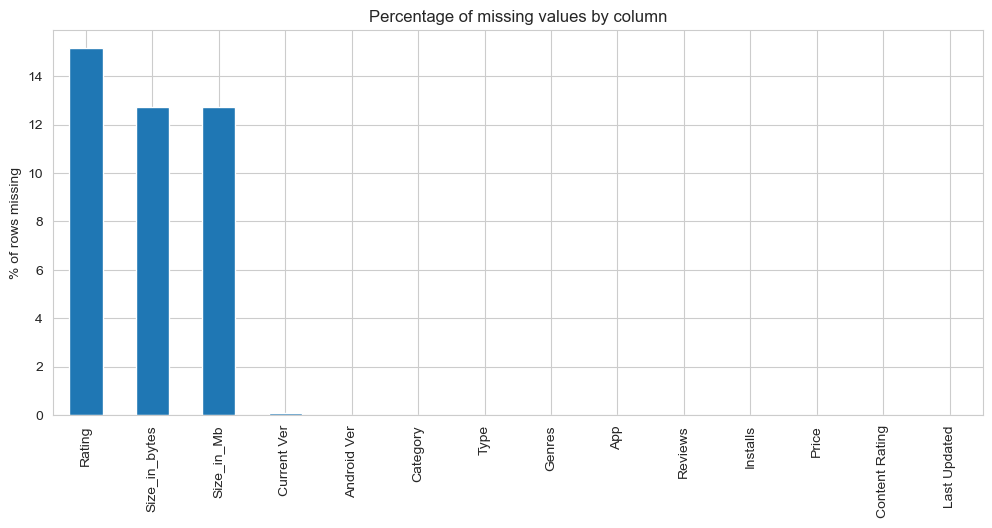

In [32]:
plt.figure(figsize=(12, 5))
missing_percent.plot(kind='bar')
plt.ylabel('% of rows missing')
plt.title('Percentage of missing values by column')
plt.show()

- And a heatmap of the whole table. Each thin horizontal line is a row; bright marks are gaps.
This one answers a different question: are the gaps **spread evenly**, or do they cluster in one part of the file?

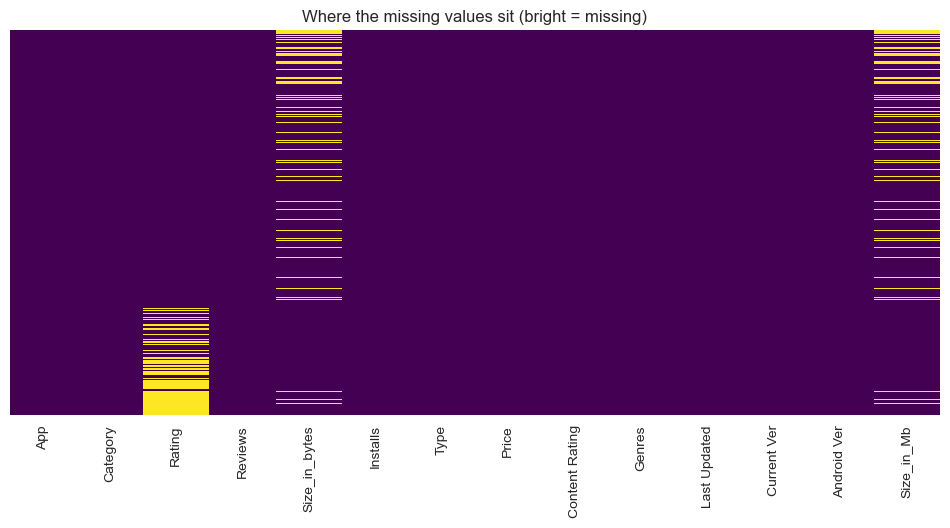

In [33]:
plt.figure(figsize=(12, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title('Where the missing values sit (bright = missing)')
plt.show()

## Observations
---
- `Rating` is missing in about 15% of rows - far too many to simply drop.
- `Size_in_bytes` / `Size_in_Mb` are missing in about 13% - but those are the `'Varies with device'` apps, so
  the reason is already known.
- `Current Ver`, `Android Ver`, `Category`, `Type` and `Genres` are missing in only a handful of rows each.
- The heatmap shows the `Rating` gaps scattered throughout rather than clumped in one block, so this is not a
  "the scraper died halfway" problem.

Three different situations, so three different decisions below.
---

### 5.1 The easy ones - drop them

`Category`, `Type`, `Genres`, `Current Ver` and `Android Ver` are missing in a tiny number of rows. Dropping
those rows loses a rounding error's worth of data and saves a lot of special-casing later.

`subset=[...]` means "only drop a row if **these** columns are missing" - without it, `dropna()` would drop
every row that is missing a `Rating` too, which is 13% of the dataset.

In [34]:
rows_before = len(df)

df = df.dropna(subset=['Category', 'Type', 'Genres', 'Current Ver', 'Android Ver'])

print(f"Dropped {rows_before - len(df)} rows")
print(f"{len(df)} rows left")

Dropped 12 rows
9648 rows left


### 5.2 `Size` - deliberately leave it missing

`Size_in_Mb` is missing in exactly the rows where the app said *"Varies with device"*. The real size depends on
the user's phone, so there is no true value to fill in. Inventing one (say, the category average) would
manufacture data that never existed.

**Leaving a gap as a gap is a legitimate decision**, as long as it is a decision and not an oversight.

### 5.3 `Rating` - the one that needs thought

15% is too much to drop and too much to fill carelessly. So first: **is it missing at random, or for a reason?**

The hypothesis: an app with very few installs simply hasn't been rated by enough people yet to have a rating at
all. If that is true, the missing ratings will be concentrated in the low-install apps - and filling them all
with one global average of about 4.2 would make tiny unproven apps look as good as established ones.

Testing that needs install **buckets** to group by.

`pd.cut()` slices a numeric column into ranges and labels each range. The first edge is `-1` rather than `0`
so that apps with exactly 0 installs fall inside the first bucket (the left edge is exclusive).

In [35]:
bins   = [-1, 0, 10, 1000, 10000, 100000, 1000000, 10000000, 10000000000]
labels = ['0', '1-10', '11-1K', '1K-10K', '10K-100K', '100K-1M', '1M-10M', '10M+']

df['Installs_category'] = pd.cut(df['Installs'], bins=bins, labels=labels)

df['Installs_category'].value_counts().sort_index()   # sort_index() keeps them in size order, not count order

Installs_category
0             14
1-10         533
11-1K       2125
1K-10K      1495
10K-100K    1581
100K-1M     1919
1M-10M      1544
10M+         437
Name: count, dtype: int64

- Now a flag column marking every row whose rating is missing.

It earns its place twice: right now it diagnoses *where* the gaps are, and after the fill it stays behind as a
permanent record of which ratings were invented rather than observed.

In [36]:
df['Rating_imputed'] = df['Rating'].isnull()   # True wherever the rating is missing

df['Rating_imputed'].sum()

1458

- The actual test: what **share** of each install bucket is missing a rating?

Averaging a True/False column gives the *proportion* of Trues (because True is 1 and False is 0), so
multiplying by 100 gives a percentage. It is the simplest way to ask "what share of this group is X?".

In [37]:
missing_by_bucket = df.groupby('Installs_category', observed=True)['Rating_imputed'].mean() * 100

missing_by_bucket.round(1)

Installs_category
0           100.0
1-10         84.8
11-1K        41.1
1K-10K        5.8
10K-100K      1.9
100K-1M       0.2
1M-10M        0.0
10M+          0.0
Name: Rating_imputed, dtype: float64

## Observations
---
The pattern is unmistakable. Ratings are missing in **100%** of the zero-install apps and about **85%** of the
`1-10` install apps, falling to **0%** in the `1M-10M` and `10M+` buckets. The values are **not** missing at
random - they are missing *because* the app is small.

So the decision: fill each missing rating with the **median rating of its own install bucket**, not with one
global number. A tiny app gets the typical rating of tiny apps.

> Median rather than mean, because the median is not dragged around by a few extreme values.
---

- Now the fill itself.

`groupby(...).transform('median')` needs one sentence of explanation, because it is the one piece of pandas
magic in this notebook: it computes the median per group, then hands back a column **the same length as the
DataFrame**, where every row already carries its own group's median. That alignment is what lets `fillna()`
use it directly.

In [38]:
bucket_median = df.groupby('Installs_category', observed=True)['Rating'].transform('median')

# fillna() only touches the gaps - ratings that already exist are left exactly as they were
df['Rating'] = df['Rating'].fillna(bucket_median)

print(f"Ratings still missing: {df['Rating'].isnull().sum()}")

Ratings still missing: 14


- **Never assume a fill worked.** That count should be zero, and it isn't - 14 ratings survived the fill.
Worth finding out which ones before going any further.

In [39]:
leftover = df.loc[df['Rating'].isnull(), 'Installs_category'].value_counts()

leftover[leftover > 0]

Installs_category
0    14
Name: count, dtype: int64

## Observations
---
All 14 are in the `'0'` bucket - the apps with zero installs. Look back at the table above: that bucket is
**100% missing**. Every single app in it lacks a rating, so there was no median inside the group to borrow,
`transform('median')` returned `NaN`, and `fillna()` had nothing to put in.

This is the honest limit of group-wise filling: **it can only borrow from a group that has something to lend.**

An app with zero installs and no rating carries no information for any question in this notebook, so those 14
rows get dropped rather than filled with a number invented from a different group.
---

In [40]:
rows_before = len(df)

df = df.dropna(subset=['Rating'])

print(f"Dropped {rows_before - len(df)} rows with no rating and no group to borrow one from")
print(f"Rows left:      {len(df)}")
print(f"Ratings filled: {df['Rating_imputed'].sum()}  ({df['Rating_imputed'].mean() * 100:.1f}% of the data)")

Dropped 14 rows with no rating and no group to borrow one from
Rows left:      9634
Ratings filled: 1444  (15.0% of the data)


- **Always check that filling gaps did not distort the column.** Same column, before and after, side by side.

`plt.subplots(1, 2)` creates one row of two charts and provides `axes[0]` and `axes[1]` to draw into.
The `~` symbol means NOT, so `~df['Rating_imputed']` selects the rows that were *not* filled.

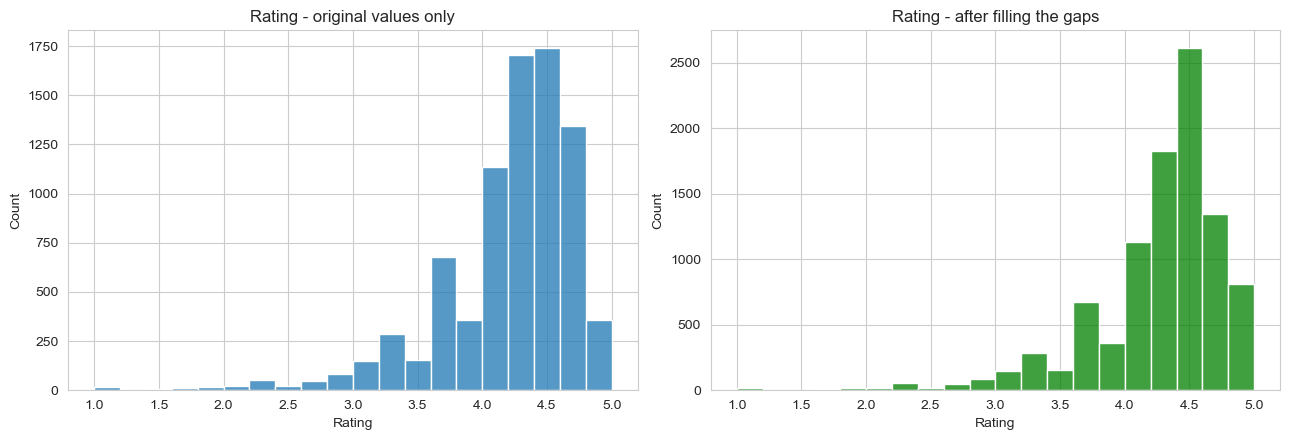

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

original_only = df.loc[~df['Rating_imputed'], 'Rating']
sns.histplot(original_only, bins=20, ax=axes[0])
axes[0].set_title('Rating - original values only')

sns.histplot(df['Rating'], bins=20, ax=axes[1], color='green')
axes[1].set_title('Rating - after filling the gaps')

plt.tight_layout()
plt.show()

## Observations
---
The two shapes are essentially the same - same peak around 4.3, same left tail. That is exactly the goal:
if the right-hand chart had grown a new spike, it would mean the filling had invented a pattern that was not in
the data. It did not, so carry on.
---

---
## 6. Building the columns actually needed

Raw columns rarely answer a question directly. Three small additions here, each one because a question later
in the notebook needs it.

### 6.1 How recently was each app updated?

`Last Updated` is text like `'January 7, 2018'`. As text it cannot be subtracted. `pd.to_datetime()` turns it into
a real date; `format='%B %d, %Y'` spells out the layout (`%B` = full month name, `%d` = day, `%Y` = 4-digit year)
so pandas doesn't have to guess. `errors='coerce'` turns anything unreadable into `NaT` (a missing date)
instead of crashing the whole cell.

In [42]:
df['Last Updated'] = pd.to_datetime(df['Last Updated'], format='%B %d, %Y', errors='coerce')

# This data is a snapshot, so "today" means the newest date inside it - not the real today.
latest_date = df['Last Updated'].max()

# Subtracting two dates gives a duration; .dt.days pulls out the whole number of days.
df['Days_Since_Update'] = (latest_date - df['Last Updated']).dt.days

print(f"Newest update date in the data: {latest_date.date()}")

Newest update date in the data: 2018-08-08


### 6.2 A single main genre

`Genres` holds combinations like `'Art & Design;Creativity'`, which gives over a hundred near-duplicate groups -
too fragmented to chart. `.str.split(';')` breaks each value into a list, and `.str[0]` takes the first item.

In [43]:
df['Primary_Genre'] = df['Genres'].str.split(';').str[0]

print(f"Unique genre combinations: {df['Genres'].nunique()}")
print(f"Unique primary genres:     {df['Primary_Genre'].nunique()}")

Unique genre combinations: 118
Unique primary genres:     48


### 6.3 Price bands

Same `pd.cut()` idea as the install buckets. `-0.01` as the first edge so that free apps (price exactly 0)
land in the `'Free'` band.

In [44]:
price_bins   = [-0.01, 0, 5, 15, 500]
price_labels = ['Free', '$0.01 - $5', '$5 - $15', '$15+']

df['Price_Tier'] = pd.cut(df['Price'], bins=price_bins, labels=price_labels)

df['Price_Tier'].value_counts().sort_index()

Price_Tier
Free          8893
$0.01 - $5     590
$5 - $15       103
$15+            48
Name: count, dtype: int64

---
## 7. One column at a time (univariate analysis)

The temptation is to jump straight to "what drives installs?". Resist it. Without knowing the shape of a column
on its own, every comparison involving it gets misread.

### 7.1 Which categories are most common?

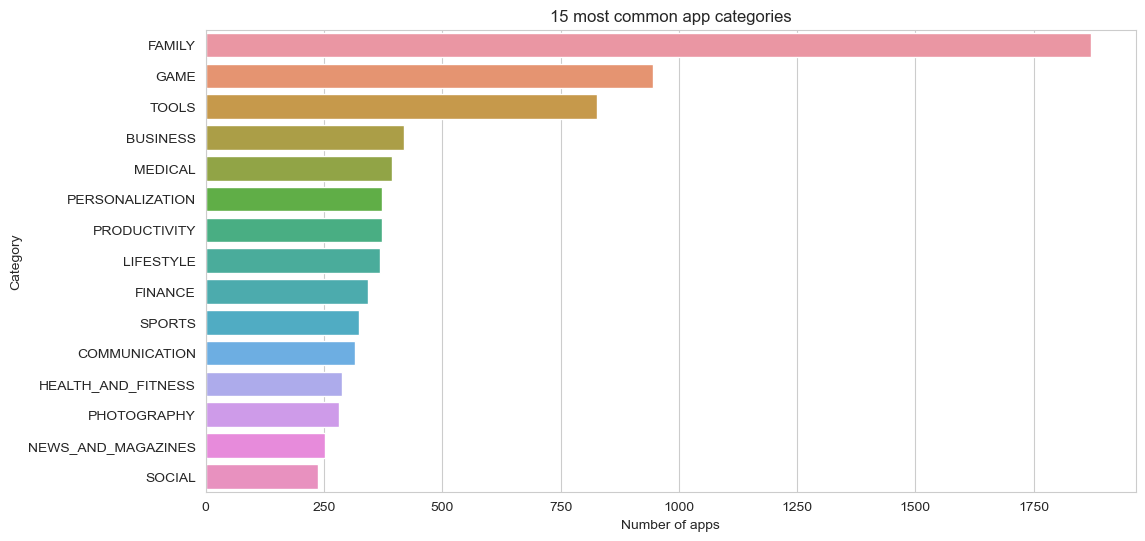

In [45]:
top_categories = df['Category'].value_counts().head(15)   # the 15 most common

plt.figure(figsize=(12, 6))
sns.barplot(x=top_categories.values, y=top_categories.index)   # horizontal: category names are long
plt.xlabel('Number of apps')
plt.title('15 most common app categories')
plt.show()

## Observations
---
FAMILY and GAME dominate by sheer number of apps. Keep in mind this is **app count**, not popularity - a
category can be crowded with apps nobody installs. Section 8.1 separates those two ideas.
---

### 7.2 How are ratings distributed?

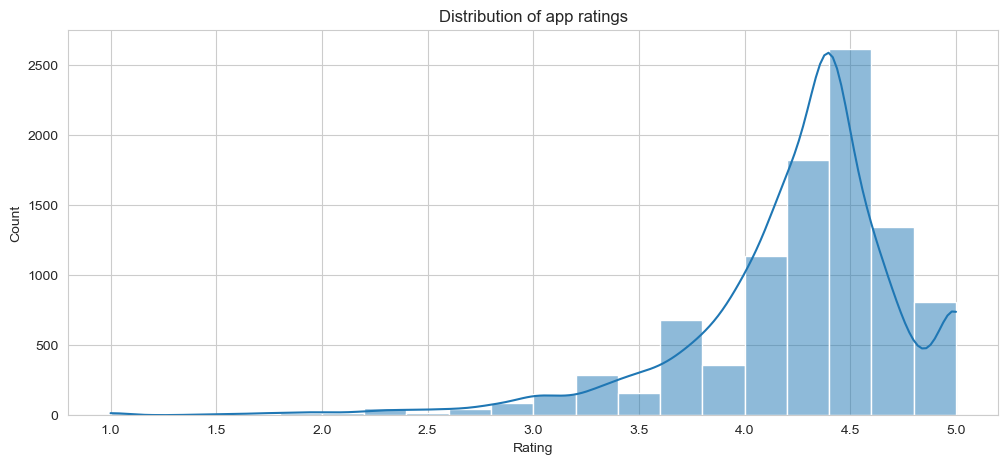

In [46]:
plt.figure(figsize=(12, 5))
sns.histplot(df['Rating'], bins=20, kde=True)   # kde=True draws the smooth curve over the bars
plt.title('Distribution of app ratings')
plt.show()

## Observations
---
Strongly left-skewed: most apps sit between 4.0 and 4.5, with a thin tail below 3. That makes sense - genuinely
bad apps get abandoned or pulled, so what remains on the store is self-selected to be decent.

Practical consequence: a 4.0 rating is **below average** here, not above it. Context changes the meaning of a number.
---

### 7.3 Reviews and installs - and why logs

`Reviews` runs from 0 to 78 million. Plotted raw, the handful of giants stretch the axis so far that 99% of the
apps collapse into a single bar at the left and nothing is visible.

`log10` fixes this: it turns 1,000 into 3 and 1,000,000 into 6, so **each step along the axis means "ten times
bigger"**. The giants and the tiny apps become visible in the same picture. Add 1 first because `log10(0)` is
undefined and some apps genuinely have 0 reviews.

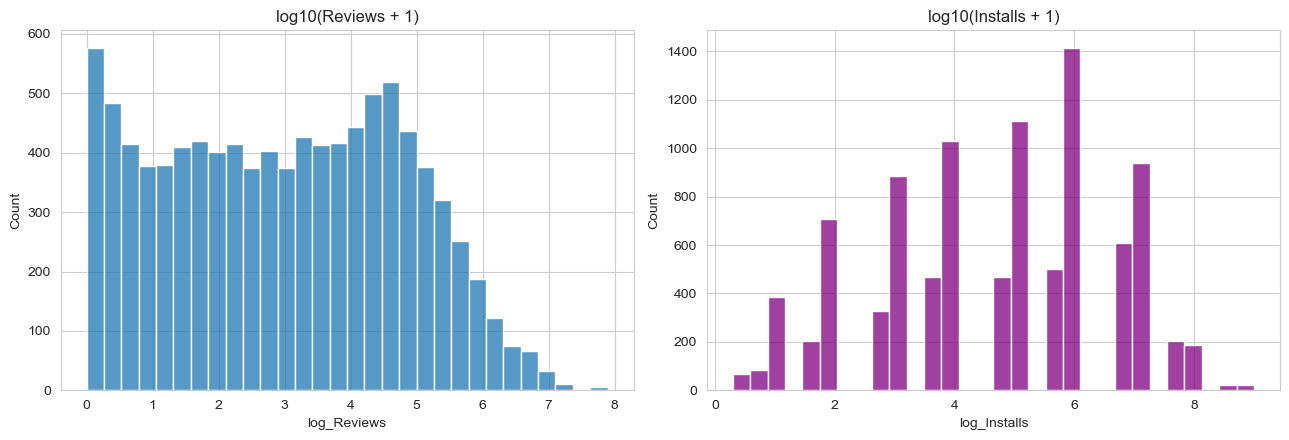

In [47]:
df['log_Reviews']  = np.log10(df['Reviews'] + 1)
df['log_Installs'] = np.log10(df['Installs'] + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(df['log_Reviews'], bins=30, ax=axes[0])
axes[0].set_title('log10(Reviews + 1)')

sns.histplot(df['log_Installs'], bins=30, ax=axes[1], color='purple')
axes[1].set_title('log10(Installs + 1)')

plt.tight_layout()
plt.show()

## Observations
---
Both are roughly bell-shaped **once logged**, which is the classic signature of data that is multiplicative
rather than additive. The `Installs` chart is spiky rather than smooth because the source values are bucketed
(`10,000+`, `50,000+`, ...) rather than exact counts.

From here on, any chart or test involving reviews or installs uses the logged version.
---

### 7.4 Free versus paid

In [48]:
df['Type'].value_counts()

Type
Free    8893
Paid     741
Name: count, dtype: int64

In [49]:
paid_apps = df[df['Price'] > 0]

print(f"Paid apps: {len(paid_apps)}  ({len(paid_apps) / len(df) * 100:.1f}% of the store)")
paid_apps['Price'].describe()

Paid apps: 741  (7.7% of the store)


count    741.000000
mean      12.671080
std       55.191122
min        0.990000
25%        1.490000
50%        2.990000
75%        4.990000
max      400.000000
Name: Price, dtype: float64

- And what paid apps actually charge.

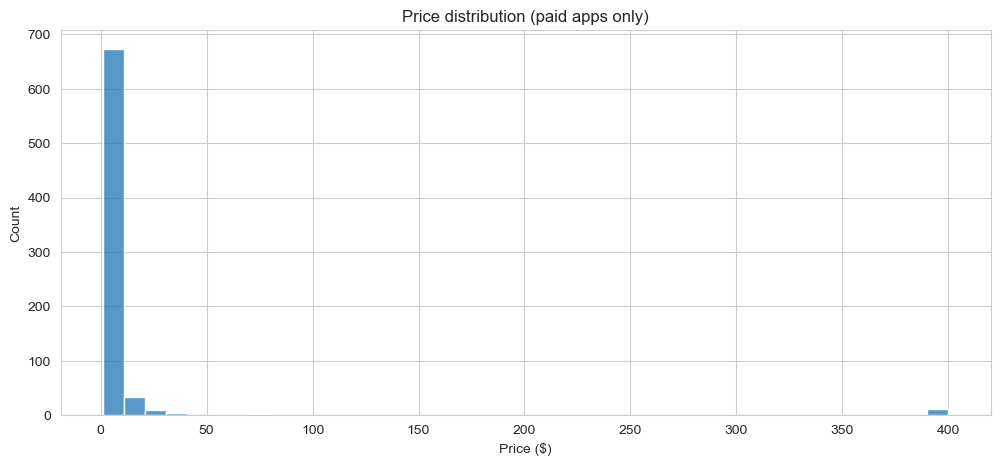

In [50]:
plt.figure(figsize=(12, 5))
sns.histplot(paid_apps['Price'], bins=40)
plt.title('Price distribution (paid apps only)')
plt.xlabel('Price ($)')
plt.show()

## Observations
---
About 92% of the store is free, and even the paid apps cluster below $5, with a thin tail of expensive
outliers. Those outliers are worth a direct look later - see section 11.3.
---

---
## 8. Two columns together (bivariate analysis)

This is where the actual insight lives. Each subsection below pairs one question with one chart.

### 8.1 Category versus installs - which categories are crowded?

`groupby('Category')['Installs'].agg([...])` splits the table by category and computes several statistics at once.
Three are useful here:
- **count** - how many apps compete in this category
- **median** - what a *typical* app in it achieves
- **sum** - the total size of the prize

In [51]:
cat_installs = df.groupby('Category', observed=True)['Installs'].agg(['count', 'median', 'sum'])
cat_installs = cat_installs.sort_values('sum', ascending=False)

cat_installs.head(10)

,count,median,sum
Category,,,
GAME,945,1000000.0,13447924415
COMMUNICATION,315,100000.0,11038276251
TOOLS,827,50000.0,8102271905
FAMILY,1872,50000.0,6237482405
PRODUCTIVITY,373,100000.0,5793091369
SOCIAL,237,100000.0,5487867902
PHOTOGRAPHY,281,1000000.0,4658147655
VIDEO_PLAYERS,164,1000000.0,3931902720
TRAVEL_AND_LOCAL,218,100000.0,2894887146


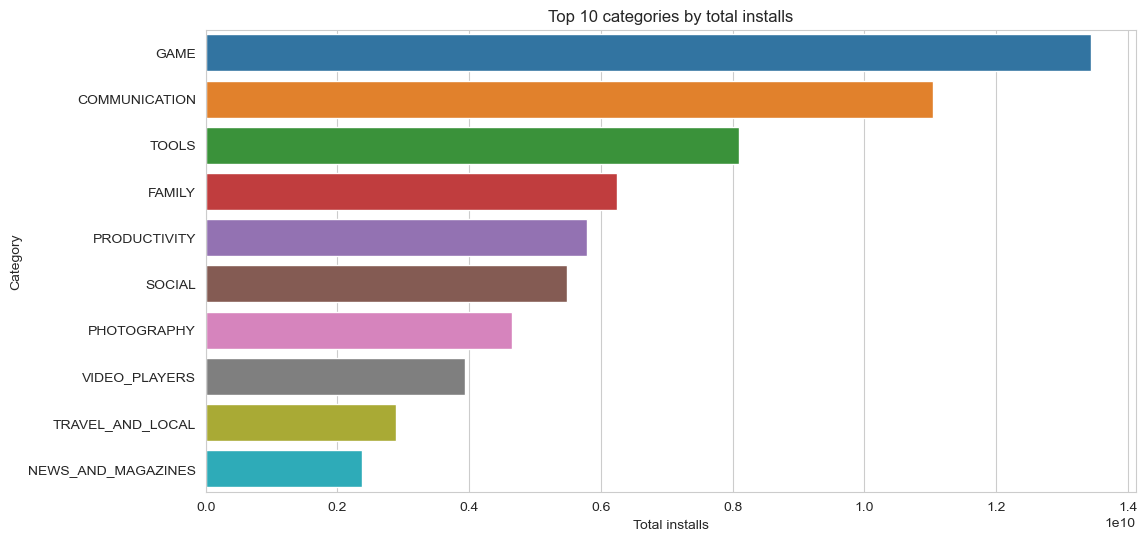

In [52]:
top10 = cat_installs.head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=top10['sum'], y=top10.index)
plt.xlabel('Total installs')
plt.title('Top 10 categories by total installs')
plt.show()

- Now the opposite view: which categories have plenty of apps but a low **typical** install count?

In [53]:
crowded = cat_installs.sort_values('median')

crowded[['count', 'median']].head(10)

,count,median
Category,,
BUSINESS,419,1000.0
MEDICAL,394,1000.0
EVENTS,64,1000.0
LIFESTYLE,368,10000.0
LIBRARIES_AND_DEMO,83,10000.0
DATING,170,10000.0
FINANCE,343,10000.0
PERSONALIZATION,373,10000.0
BOOKS_AND_REFERENCE,221,10000.0


## Observations
---
GAME, COMMUNICATION and SOCIAL take the most total installs by a wide margin.

But the second table is the more useful one. Some categories carry a large number of apps while the *median*
app in them gets very few installs - that is a crowded market where nobody in particular is winning. For advice
on where to launch, **that** is the signal, not raw app count.

> The general lesson of comparing `sum` against `median`: the total tells you how big the prize is, the
> median tells you your realistic share of it.
---

### 8.2 Category versus rating

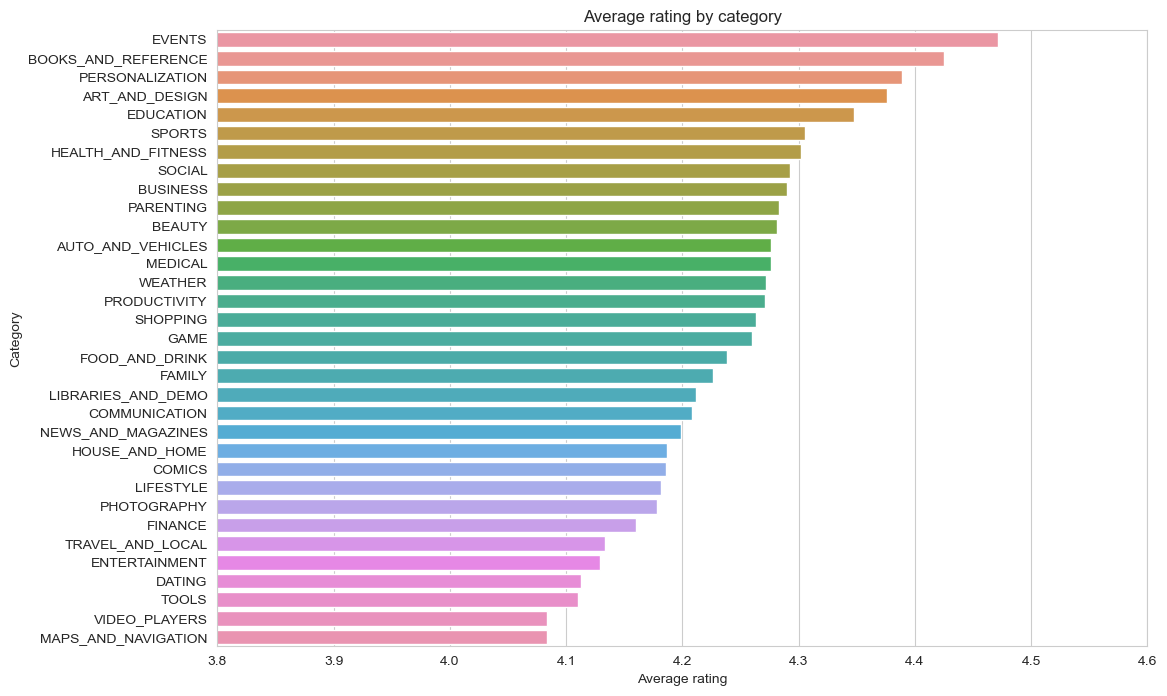

In [54]:
cat_rating = df.groupby('Category', observed=True)['Rating'].mean().sort_values(ascending=False)

plt.figure(figsize=(12, 8))
sns.barplot(x=cat_rating.values, y=cat_rating.index)
plt.xlim(3.8, 4.6)     # zoom the axis - every category sits in a narrow band, so from 0 you'd see nothing
plt.xlabel('Average rating')
plt.title('Average rating by category')
plt.show()

> Note the `plt.xlim(3.8, 4.6)`. Every category averages between about 3.9 and 4.5, so starting the axis at
> zero would give thirty identical-looking bars. Zooming in is the right call here - but it does exaggerate the
> differences, so say so out loud rather than letting the chart oversell a tiny gap.

### 8.3 Free versus paid - do they behave differently?

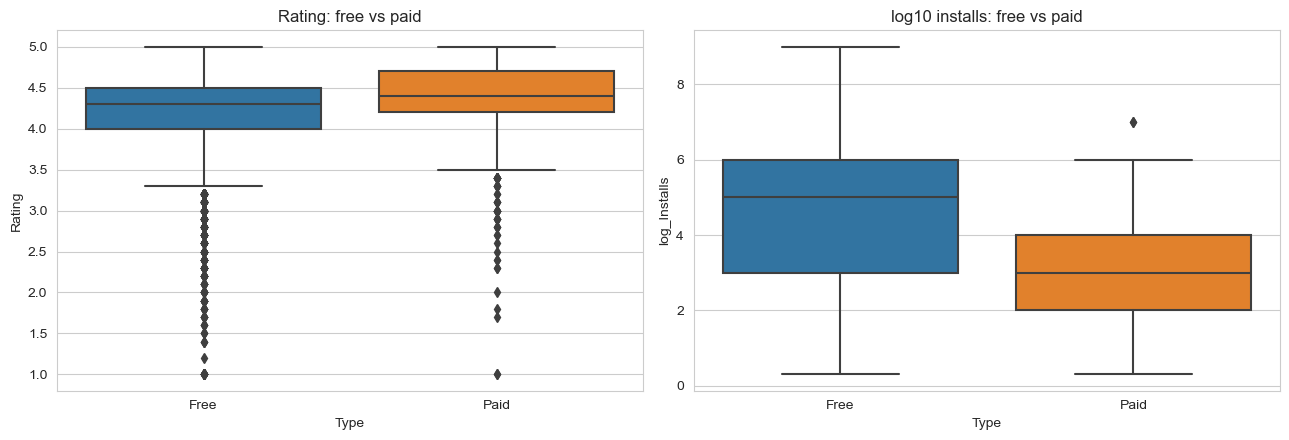

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.boxplot(x='Type', y='Rating', data=df, ax=axes[0])
axes[0].set_title('Rating: free vs paid')

sns.boxplot(x='Type', y='log_Installs', data=df, ax=axes[1])
axes[1].set_title('log10 installs: free vs paid')

plt.tight_layout()
plt.show()

> **Reading a boxplot:** the line in the box is the median, the box covers the middle 50% of apps, the
> whiskers reach most of the rest, and the dots beyond them are outliers. It is the fastest way to compare two
> groups without assuming either is bell-shaped.

## Observations
---
Paid apps rate slightly higher but get dramatically fewer installs. A plausible reading: paying up front
selects for people who actually wanted the app, so they rate it more kindly - but most people simply won't pay,
which caps the install ceiling.

That is a *story*, not a proof. The rating gap gets tested properly in section 10.3.
---

### 8.4 Content rating versus installs

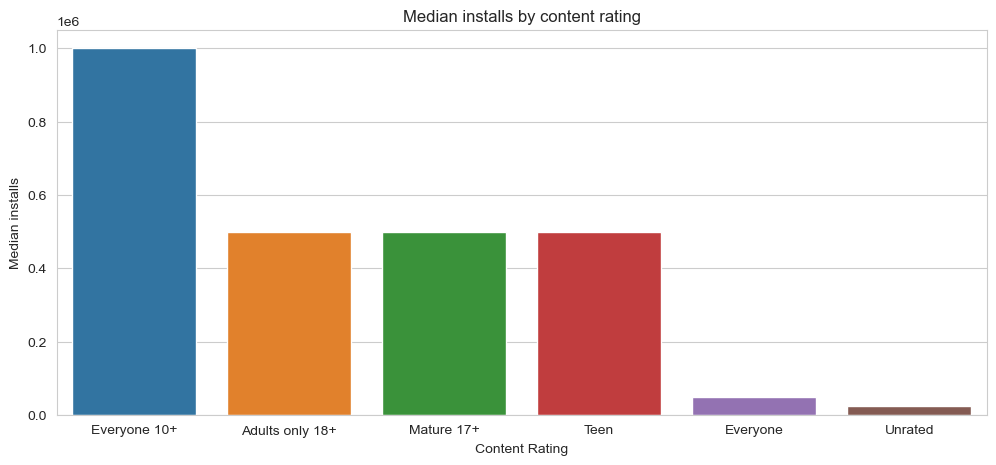

In [56]:
content_installs = df.groupby('Content Rating', observed=True)['Installs'].median()
content_installs = content_installs.sort_values(ascending=False)

plt.figure(figsize=(12, 5))
sns.barplot(x=content_installs.index, y=content_installs.values)
plt.ylabel('Median installs')
plt.title('Median installs by content rating')
plt.show()

### 8.5 Does app size relate to installs or rating?

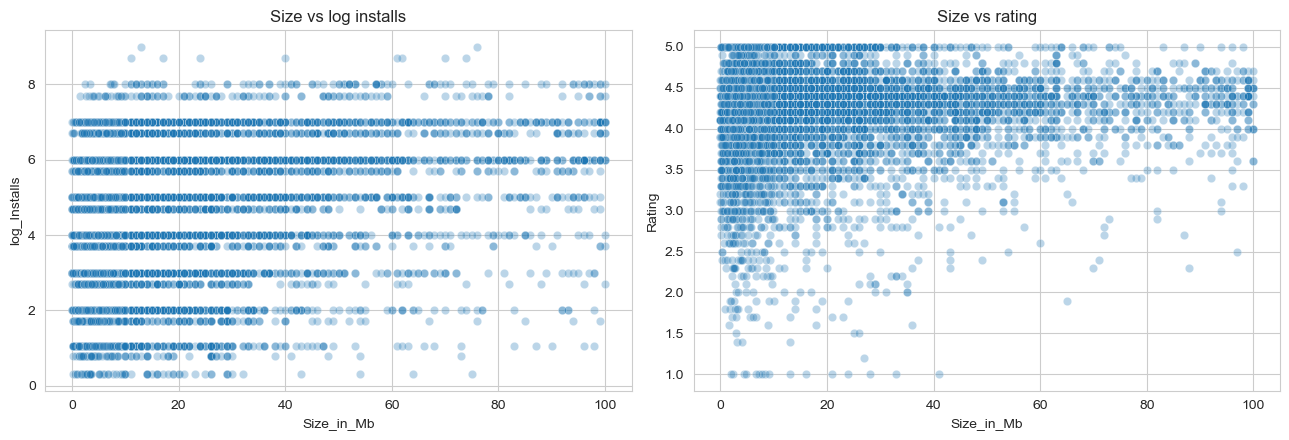

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# alpha=0.3 makes each dot semi-transparent, so dense areas show up darker instead of one solid blob
sns.scatterplot(x='Size_in_Mb', y='log_Installs', data=df, alpha=0.3, ax=axes[0])
axes[0].set_title('Size vs log installs')

sns.scatterplot(x='Size_in_Mb', y='Rating', data=df, alpha=0.3, ax=axes[1])
axes[1].set_title('Size vs rating')

plt.tight_layout()
plt.show()

## Observations
---
No clean trend in either chart - just a cloud. It is tempting to squint and find a shape in a cloud, so this
gets confirmed numerically in the correlation matrix rather than trusted by eye.
---

### 8.6 Does updating recently go with a better rating?

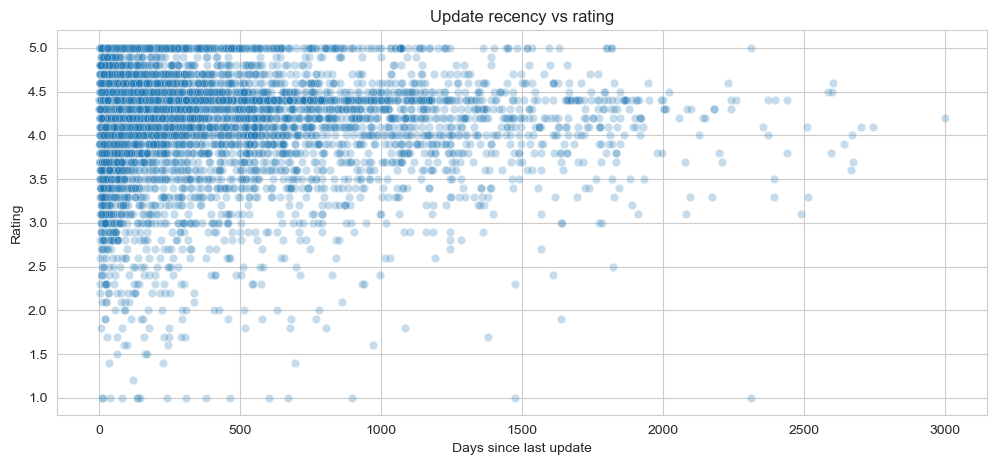

In [58]:
plt.figure(figsize=(12, 5))
sns.scatterplot(x='Days_Since_Update', y='Rating', data=df, alpha=0.25)
plt.xlabel('Days since last update')
plt.title('Update recency vs rating')
plt.show()

## Observations
---
The dense band on the left is simply where most apps live (recently updated). There is a visible thinning of
high ratings among apps not touched for a very long time, but it is weak. Again - the correlation matrix next.
---

---
## 9. Correlation - which pairs deserve attention

A correlation matrix measures how strongly each pair of numeric columns moves together, on a scale from -1 to
+1. It is the fastest way to decide **what to investigate next**.

Two cautions:
- Correlation measures a **straight-line** relationship only. That is exactly why the logged versions of
  reviews and installs go in - the raw relationship is curved, and the raw correlation would understate it.
- Correlation is not causation. It says two things move together, never which one moves the other.

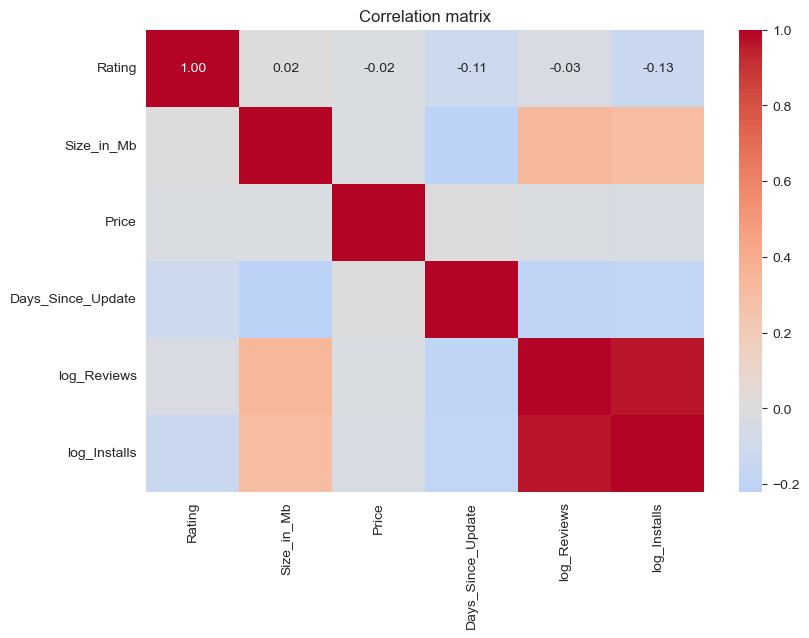

In [59]:
# Build a small table of just the numeric columns worth comparing
corr_cols = df[['Rating', 'Size_in_Mb', 'Price', 'Days_Since_Update', 'log_Reviews', 'log_Installs']]

plt.figure(figsize=(9, 6))
sns.heatmap(corr_cols.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation matrix')
plt.show()

> `annot=True` prints the number inside each square, `fmt='.2f'` rounds it to 2 decimals, and `center=0`
> puts the neutral colour at zero so positive and negative correlations are visually opposite.

## Observations
---
- `log_Reviews` and `log_Installs` are strongly correlated - by far the strongest pair in the table. More
  installs, more reviews. Obvious, but it is good to see the data confirm the obvious before trusting it on
  the non-obvious.
- `Size_in_Mb`, `Price` and `Days_Since_Update` each correlate only weakly with rating and installs. The
  scatterplots in 8.5 and 8.6 were telling the truth: **size and price do not explain success on their own.**
- That is itself a finding. "The thing everyone assumes matters doesn't, in this data" is worth reporting.
---

---
## 10. Testing the patterns properly

A chart that *looks* like a pattern is not the same as a pattern. Three quick tests here, each with the
question it answers in plain language.

The number to read in all of them is the **p-value**: roughly, "if there were really no effect, how likely is a
result this extreme by chance?" A very small p-value means the pattern is unlikely to be noise.

> A p-value tells you whether an effect is **real**. It does not tell you whether it is **big**. Those are
> different questions, and section 10.3 is a good example of why the distinction matters.

In [60]:
from scipy import stats

### 10.1 Do reviews really track installs?

**Pearson correlation** measures the strength of a straight-line relationship between two numeric columns.
Applied to the logged values, for the reason given in section 9.

In [61]:
r, p = stats.pearsonr(df['log_Reviews'], df['log_Installs'])

print(f"Correlation r = {r:.3f}")
print(f"p-value       = {p:.2e}")

Correlation r = 0.959
p-value       = 0.00e+00


## Observations
---
Very strong, and the p-value is effectively zero. Reviews are a reliable stand-in for install volume when exact
install numbers aren't available - a genuinely useful thing to know.
---

### 10.2 Does rating really differ across install buckets?

This matters because it is the assumption the missing-value fill in section 5.3 was built on. If ratings do
*not* differ by install bucket, filling per bucket was pointless.

**Kruskal-Wallis** compares more than two groups without assuming the data is bell-shaped - the right choice
here, since section 7.2 showed `Rating` is clearly skewed.

In [62]:
# Build a list holding each bucket's ratings, one entry per bucket
groups = []
for bucket_name, bucket_rows in df.groupby('Installs_category', observed=True):
    groups.append(bucket_rows['Rating'].values)

h, p = stats.kruskal(*groups)   # the * hands each group to the function as a separate argument

print(f"H statistic = {h:.2f}")
print(f"p-value     = {p:.2e}")

H statistic = 1724.52
p-value     = 0.00e+00


## Observations
---
Significant - ratings genuinely differ across install buckets. That retroactively justifies filling missing
ratings per bucket rather than with one global average.

> Worth noticing what just happened: a cleaning decision made in section 5 got **checked** in section 10.
> Decisions early in an EDA should be testable later, not just asserted.
---

### 10.3 Is the free-versus-paid rating gap real?

**Mann-Whitney U** compares exactly two groups, again without assuming a bell shape.

In [63]:
free_ratings = df.loc[df['Type'] == 'Free', 'Rating']
paid_ratings = df.loc[df['Type'] == 'Paid', 'Rating']

u, p = stats.mannwhitneyu(free_ratings, paid_ratings)

print(f"Median rating, free apps: {free_ratings.median()}")
print(f"Median rating, paid apps: {paid_ratings.median()}")
print(f"p-value = {p:.2e}")

Median rating, free apps: 4.3
Median rating, paid apps: 4.4
p-value = 5.97e-20


## Observations
---
Statistically significant - but look at the actual medians. The gap is around a tenth of a rating point.

This is the clearest illustration of the warning above: with nearly 10,000 rows, even a trivial difference
comes back "significant". **Significant does not mean important.** Report this as "paid apps rate
marginally higher", never as "paid apps are better".
---

---
## 11. Answering some specific questions

Everything above was groundwork. These are the questions worth asking once the data is trustworthy.

### 11.1 The top 5 free apps by review count

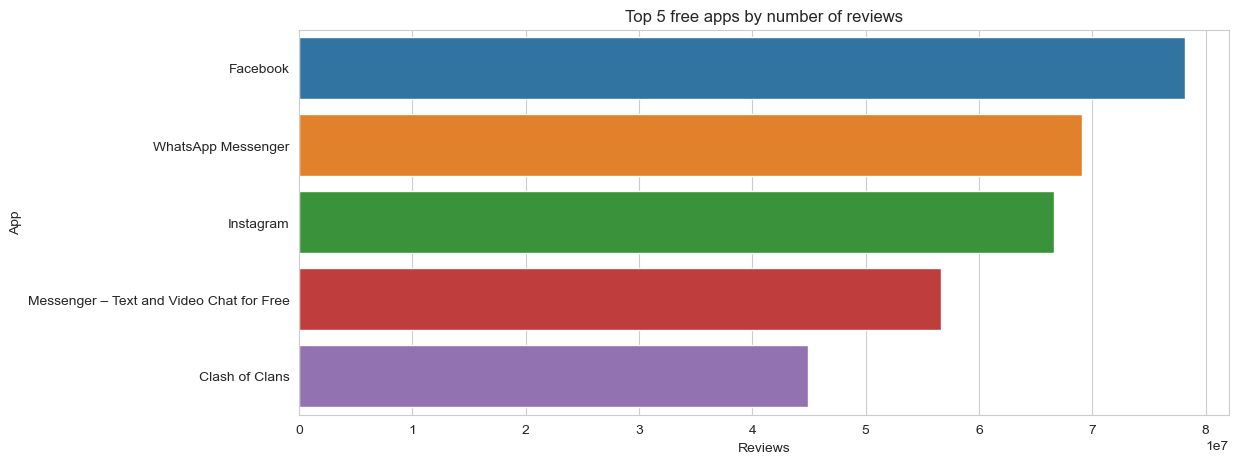

,App,Category,Reviews,Rating
0,Facebook,SOCIAL,78158306,4.1
1,WhatsApp Messenger,COMMUNICATION,69119316,4.4
2,Instagram,SOCIAL,66577446,4.5
3,Messenger – Text and Video Chat for Free,COMMUNICATION,56646578,4.0
4,Clash of Clans,GAME,44893888,4.6


In [64]:
top_free = df[df['Type'] == 'Free'].sort_values('Reviews', ascending=False).head(5)

plt.figure(figsize=(12, 5))
sns.barplot(x='Reviews', y='App', data=top_free)
plt.title('Top 5 free apps by number of reviews')
plt.show()

top_free[['App', 'Category', 'Reviews', 'Rating']]

### 11.2 The top 5 paid apps by review count

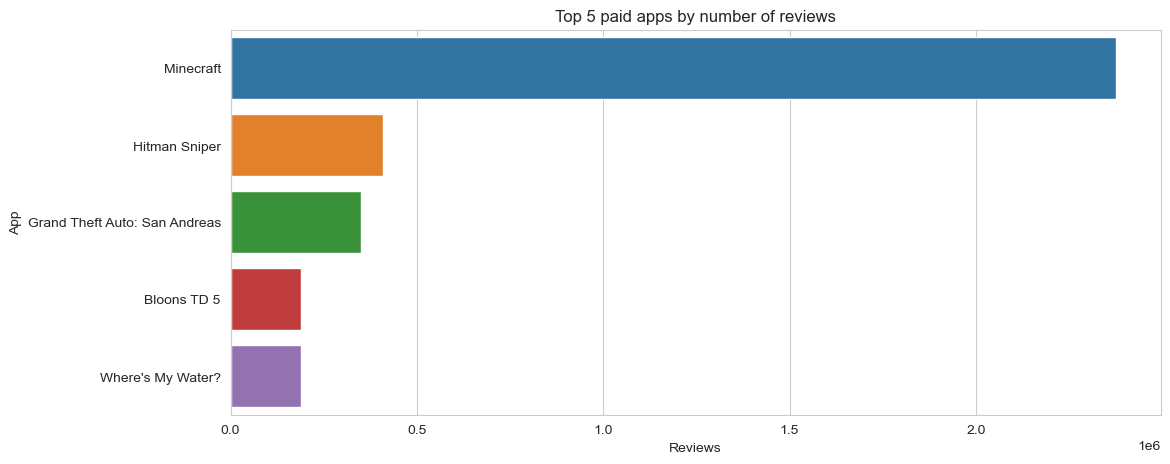

,App,Category,Reviews,Rating,Price
172,Minecraft,FAMILY,2376564,4.5,6.99
660,Hitman Sniper,GAME,408292,4.6,0.99
730,Grand Theft Auto: San Andreas,GAME,348962,4.4,6.99
1055,Bloons TD 5,FAMILY,190086,4.6,2.99
1060,Where's My Water?,FAMILY,188740,4.7,1.99


In [65]:
top_paid = df[df['Type'] == 'Paid'].sort_values('Reviews', ascending=False).head(5)

plt.figure(figsize=(12, 5))
sns.barplot(x='Reviews', y='App', data=top_paid)
plt.title('Top 5 paid apps by number of reviews')
plt.show()

top_paid[['App', 'Category', 'Reviews', 'Rating', 'Price']]

## Observations
---
Compare the axis scales on the two charts. The biggest paid apps get a small fraction of the reviews the
biggest free apps get. The price is a wall most users never get past.
---

### 11.3 The most expensive apps - are they even real?

In [66]:
expensive = df[['App', 'Category', 'Price', 'Rating']].sort_values('Price', ascending=False)

expensive.head(10)

,App,Category,Price,Rating
5648,I'm Rich - Trump Edition,LIFESTYLE,400.00,3.6
5314,I am rich(premium),FINANCE,399.99,3.5
6370,I am Rich!,FINANCE,399.99,3.8
7004,I AM RICH PRO PLUS,FINANCE,399.99,4.0
4913,I am Rich Plus,FAMILY,399.99,4.0
5031,💎 I'm rich,LIFESTYLE,399.99,3.8
3986,I am rich,LIFESTYLE,399.99,3.8
4441,I Am Rich Premium,FINANCE,399.99,4.1
8099,most expensive app (H),FAMILY,399.99,4.3
6157,I am rich (Most expensive app),FINANCE,399.99,4.1


## Observations
---
These are almost all novelty listings - the "I'm Rich" family of joke apps that exist only to be expensive.
Not premium software at all.

A useful reminder: before treating `Price` as a quality signal, **look at the actual rows at the extreme**.
The outliers here aren't data errors, but they aren't meaningful prices either.
---

### 11.4 Which genres rate best - among genres with enough apps to mean something?

The filter matters. A genre with 4 apps can top any average by luck, so require at least 30 apps before a
genre is allowed into the ranking.

In [67]:
genre_stats = df.groupby('Primary_Genre', observed=True)['Rating'].agg(['count', 'median'])

big_enough = genre_stats[genre_stats['count'] >= 30]       # ignore genres with too few apps
big_enough.sort_values('median', ascending=False).head(10)

,count,median
Primary_Genre,,
Books & Reference,224,4.5
Weather,79,4.4
Comics,56,4.4
Medical,394,4.4
Lifestyle,369,4.4
Productivity,373,4.4
Puzzle,141,4.4
Health & Fitness,290,4.4
Food & Drink,112,4.4


### 11.5 Which categories have the most vocal users?

Reviews divided by installs is a rough engagement measure: out of everyone who installed, what share
bothered to leave a review? `.replace(0, np.nan)` guards against dividing by zero for apps with no installs.

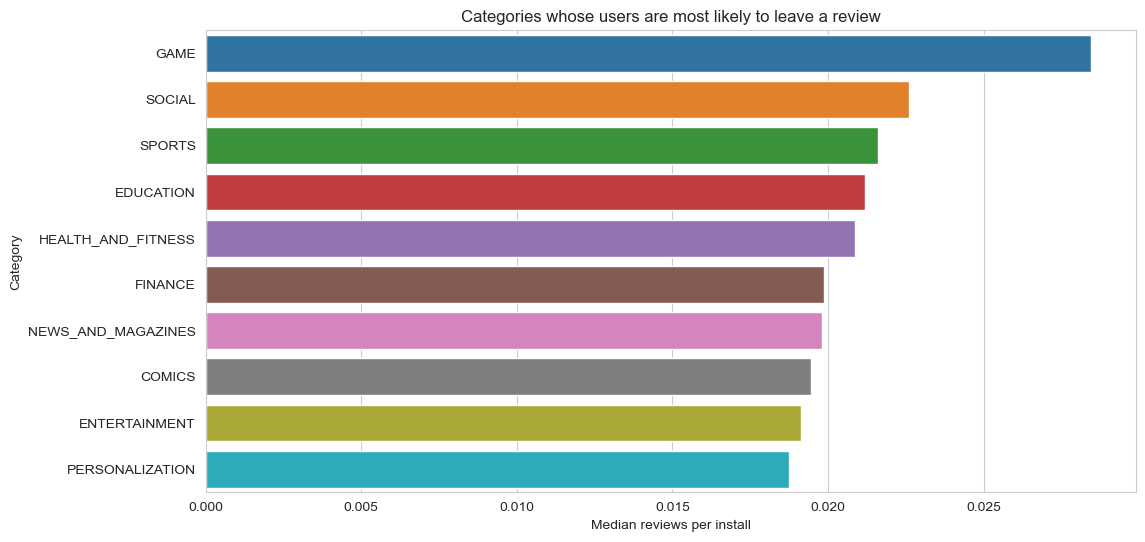

In [68]:
df['Review_Install_Ratio'] = df['Reviews'] / df['Installs'].replace(0, np.nan)

engagement = df.groupby('Category', observed=True)['Review_Install_Ratio'].median()
engagement = engagement.sort_values(ascending=False).head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=engagement.values, y=engagement.index)
plt.xlabel('Median reviews per install')
plt.title('Categories whose users are most likely to leave a review')
plt.show()

### 11.6 Which categories are maintained most actively?

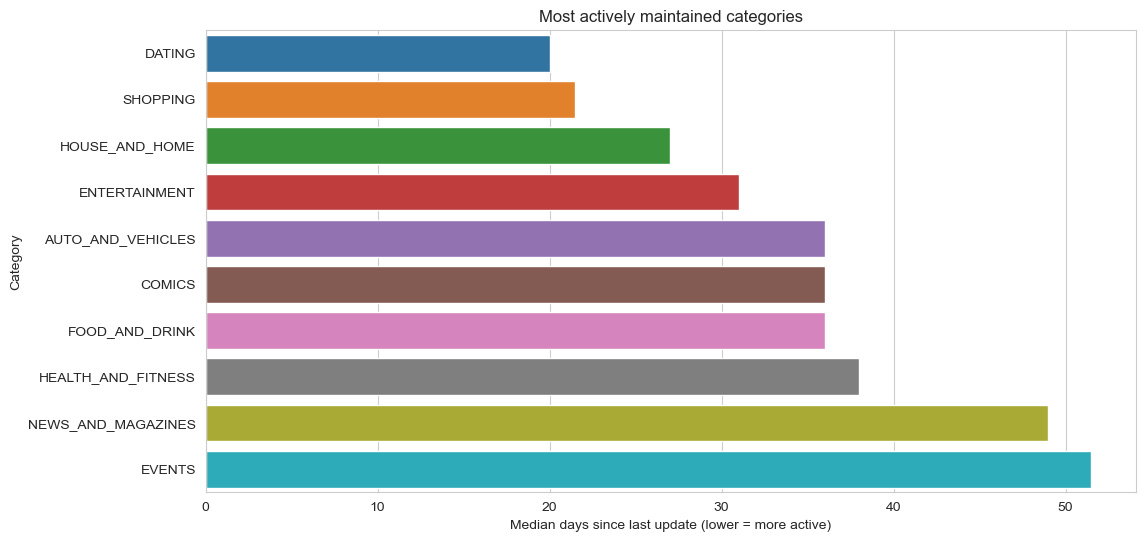

In [69]:
recency = df.groupby('Category', observed=True)['Days_Since_Update'].median()
recency = recency.sort_values().head(10)      # lower = updated more recently

plt.figure(figsize=(12, 6))
sns.barplot(x=recency.values, y=recency.index)
plt.xlabel('Median days since last update (lower = more active)')
plt.title('Most actively maintained categories')
plt.show()

### 11.7 Does charging more cost you installs?

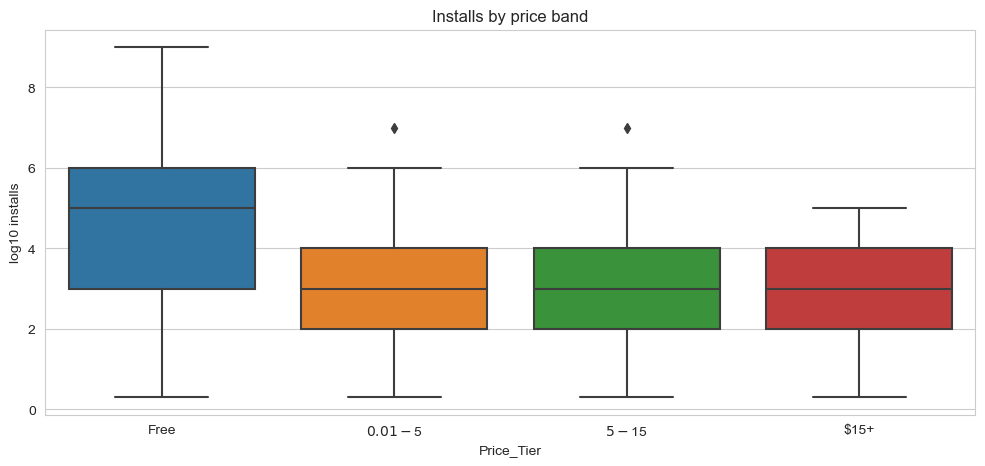

In [70]:
order = ['Free', '$0.01 - $5', '$5 - $15', '$15+']

plt.figure(figsize=(12, 5))
sns.boxplot(x='Price_Tier', y='log_Installs', data=df, order=order)
plt.ylabel('log10 installs')
plt.title('Installs by price band')
plt.show()

## Observations
---
The big drop is from free to paid-at-all. Once an app charges anything, moving from $2 to $15 doesn't appear to
cost it many more installs.

The decision that matters commercially is **whether to charge**, not how much - which is a more useful finding
than "expensive apps get fewer installs" would have been.
---

---
## 12. What the analysis actually found

- **GAME, COMMUNICATION and SOCIAL** take the most total installs - but total installs and *typical* installs
  are different questions. Several categories are crowded with apps that individually get very few installs.
  App count alone is a misleading measure of opportunity.
- **Size does not predict success.** Neither installs nor rating correlates meaningfully with app size.
- **Price barely matters once you're charging at all.** Crossing the free/paid line costs installs; the exact
  price within paid does not cost many more.
- **Reviews track installs very strongly** (confirmed statistically) - reviews are a good proxy when install
  figures aren't available.
- **Ratings genuinely differ by install volume**, which is why missing ratings were filled per install bucket
  rather than with one global average.
- **Paid apps rate marginally higher** - statistically real, but the gap is about a tenth of a point. Real, not important.
- **Ratings cluster at 4.0-4.5 storewide**, so a 4.0 app is below average, not above it.

---
## 13. What this data cannot tell me

Every EDA needs this section. Leaving it out is how an analysis gets over-trusted.

- **It's a single snapshot, not a time series.** Nothing here is a trend, no matter how it is phrased.
- **Installs are ranges, not counts.** `'10,000+'` could be 10,000 or 49,999. Every install figure here is a
  lower bound, so category totals are understated by an unknown amount.
- **About 15% of the ratings analysed are filled in, not observed.** The `Rating_imputed` flag column is
  there so this can be filtered out and the analysis re-run on observed ratings only.
- **Apps with zero installs were dropped entirely**, because none of them had a rating to keep or to borrow.
  Any conclusion here is about apps that have at least one install.
- **Some groups are tiny.** A handful of content ratings have only a few apps, so their averages are noise.
- **No revenue, retention or profit data.** "Successful" in this notebook means "many installs" - which is not
  the same as "makes money".
- **Survivorship bias.** Apps removed from the store before the scrape aren't here at all, which is part of
  why ratings look so uniformly good.
- **Correlation is not causation** anywhere in this notebook.

---
## 14. Save the cleaned data

Cleaning took most of this notebook. Saving the result means the next piece of work - a dashboard, a model,
another analysis - starts from clean data instead of repeating section 3.

`index=False` stops pandas writing the row numbers as an extra unnamed column.

In [71]:
output_path = './googleplaystore_cleaned.csv'

df.to_csv(output_path, index=False)

print(f"Saved {len(df)} rows and {df.shape[1]} columns to {output_path}")

Saved 9634 rows and 22 columns to ./googleplaystore_cleaned.csv


---
## 15. The reusable cheat sheet

For the next dataset. Same order, different column names.

### The order of operations

| Step | What's happening | The commands |
|------|------------------|--------------|
| 1 | Load and look | `pd.read_csv()`, `.head()`, `.shape`, `.columns`, `.info()`, `.describe()` |
| 2 | Find numbers stored as text | `.unique()`, `.value_counts()`, `.dtypes` |
| 3 | Fix them | `.str.replace(..., regex=False)`, `.astype(int/float)`, `.apply(my_function)` |
| 4 | Duplicates | `.duplicated().sum()`, look at examples, **then** `.drop_duplicates(subset=..., keep=...)` |
| 5 | Missing values | `.isnull().sum()`, `/ len(df) * 100`, heatmap, then decide per column |
| 6 | Fill (only if justified) | `.groupby(g)[c].transform('median')` then `.fillna()`, plus an `_imputed` flag |
| 7 | Build features | `pd.cut()`, `pd.to_datetime()`, `.str.split().str[0]`, ratios |
| 8 | One column at a time | `sns.histplot()`, `sns.barplot()` on `.value_counts()` |
| 9 | Two columns together | `.groupby().agg(['count','median','sum'])`, `sns.boxplot()`, `sns.scatterplot()` |
| 10 | Correlation | `np.log10(x + 1)` for skewed columns, then `sns.heatmap(df.corr(), annot=True)` |
| 11 | Test it | `stats.pearsonr`, `stats.kruskal`, `stats.mannwhitneyu` |
| 12 | Write it up | Findings, then limitations, then save the clean file |

### Which statistical test, and when

| Situation | Test | Line of code |
|-----------|------|--------------|
| Two numeric columns, is there a straight-line link? | Pearson | `stats.pearsonr(a, b)` |
| Two groups, do their values differ? | Mann-Whitney U | `stats.mannwhitneyu(a, b)` |
| Three or more groups, do they differ? | Kruskal-Wallis | `stats.kruskal(*groups)` |
| Two categorical columns, are they related? | Chi-square | `stats.chi2_contingency(pd.crosstab(a, b))` |

Mann-Whitney and Kruskal-Wallis are the safe defaults over t-test and ANOVA, because they don't assume the
data is bell-shaped - and real data usually isn't.

### The habits that actually matter

1. **Markdown above, Observation below.** If a cell has no observation under it, ask why it was run.
2. **Test a function on three values before applying it to ten thousand rows.**
3. **Verify every transformation against a number you already knew.** (Missing sizes should equal the
   `'Varies with device'` count.)
4. **Look at duplicates and outliers before removing them.** Decide the rule, then apply it.
5. **Ask *why* a value is missing before deciding how to fill it.** Flag anything you fill.
6. **Log-transform anything that spans orders of magnitude** before plotting or correlating.
7. **Compare `sum` against `median`** when grouping - total size of the prize versus your realistic share.
8. **Significant is not the same as important.** With thousands of rows, tiny effects test as significant.
   Report the effect size too.
9. **One idea per cell.** If explaining a cell takes a paragraph, split it.
10. **Write the limitations section.** It is the part that makes the rest trustworthy.